Reconstruct phylgeny on sampled seqs (tips) using iqtree

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from ete3 import Tree
from collections import defaultdict

import covasim as cv
from Bio import SeqIO
import networkx as nx
from scipy.stats import linregress, t as t_dist

from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf

from covasim.jhk_covasim4wastewater.intervention_search.simulation.runner import run_evo_simulation
from covasim.jhk_covasim4wastewater.intervention_search.analysis.mutation_tree import build_mutation_tree, build_infection_seq_tree, extract_sequenced_subtree, add_internal_leaves, mutation_tree_to_newick, export_fasta_from_G, set_all_branch_lengths_to_one
from covasim.jhk_covasim4wastewater.intervention_search.plotting.plot_mutation_tree import plot_mutation_tree, plot_erase_mutation_tree, plot_phylo_tree

from covasim.inference import Inference

Covasim 3.1.8 (2026-05-29) — © 2020-2026 by IDM


In [2]:
REF_FASTA     = '../sars-2-data/NC_045512_Hu-1.fasta'
FITNESS_CSV   = '../../../data/nt_fitness.csv'
ARTIC_PRIMERS = '../sars-2-data/ARTIC_V4-1.bed'
FIG_DIR = "../results"

ay4_fasta   = '../sars-2-data/variants/AY.4_consensus.fasta'
ba2_fasta   = '../sars-2-data/variants/BA.2.9_consensus.fasta'
xbb15_fasta = '../sars-2-data/variants/XBB.1.5.18_consensus.fasta'


In [3]:
sample_days = list(range(10, 61, 10))
# Routine clinical: 50 symptomatic agents per day, every 10 days.
cs_routine = cv.ClinicalSequencer(
    days      = sample_days,
    n_samples = 50,
    pool      = 'infectious', # no isolation or quarantine
    label     = 'CS_routine',
    # sequencing_batch_size defaults to 1, causing immediate release
)

In [4]:
evo_pars = dict(
    enable            = True,
    reference         = REF_FASTA,
    mol_clock_rate    = 1e-5, # ~1 substitution/genome/month at 30 000 nt = 26/29903/12
    sub_model         = 'JC', # decides which mutations happen
    fitness_model = "bloom_nt", # controls transmission rate
    fitness_data_path = FITNESS_CSV,
    store_infection_log=True,
    fitness_scale     = 0.8, 
)
sim_pars = dict(
    pop_size=1000,
    pop_type='random',
    pop_infected=10,
    start_day='2021-01-01', 
    n_days=61,
    rand_seed=1,
    verbose=0,    
    variants=[], 
    beta=0.016,
    analyzers=[cs_routine],    
    viral_dist   = dict(
        frac_time=0.3, 
        load_ratio=1, # how much more infectious the early phase is than the late phase, flat 
        high_cap=4
    ), 
    beta_dist = dict(dist='neg_binomial', par1=1.0, par2=1000, step=0.01),
    asymp_factor = 1.0, # all infectious agents transmit equally
    iso_factor   = dict(a=1.0), # isolated or quarantined agents are treated the same as everyone, does not affect sim here since no isolation or qurantine in infectious pool
    quar_factor  = dict(a=1.0),
    # rel_symp_prob   = 0.0, # everyone asymptomatic. status of disease: asymptomatic or mild (about 8 days), severe (18+ days), or death
    # rel_severe_prob = 0.0, # no one becomes severe, and therefore no one becomes critical or dies
    use_waning      = False, # true gives recovered agents partial immunity
    trans_redux     = 1.0, # Breakthrough reduction: on a first breakthrough infection, rel_trans is multiplied by trans_redux
)


sim = cv.Sim(pars=sim_pars, evo_pars=evo_pars)
sim.initialize()
sim.people.rel_sus[:]   = 1.0 # how easily this agent will be infected
sim.run()

cs_routine = sim.get_analyzer('CS_routine')

/home/eleanor124/projects/covasim4wastewater/covasim/clinical.py:194: UserWarning: ClinicalSequencer day 10: requested 50 samples but only 20 agents are available in pool='infectious'. Returning all 20 agents.
  warnings.warn(
/home/eleanor124/projects/covasim4wastewater/covasim/clinical.py:194: UserWarning: ClinicalSequencer day 20: requested 50 samples but only 29 agents are available in pool='infectious'. Returning all 29 agents.
  warnings.warn(
/home/eleanor124/projects/covasim4wastewater/covasim/clinical.py:194: UserWarning: ClinicalSequencer day 30: requested 50 samples but only 17 agents are available in pool='infectious'. Returning all 17 agents.
  warnings.warn(
/home/eleanor124/projects/covasim4wastewater/covasim/clinical.py:194: UserWarning: ClinicalSequencer day 40: requested 50 samples but only 40 agents are available in pool='infectious'. Returning all 40 agents.
  warnings.warn(


Policy B mutation tree: nodes=1000, edges=999


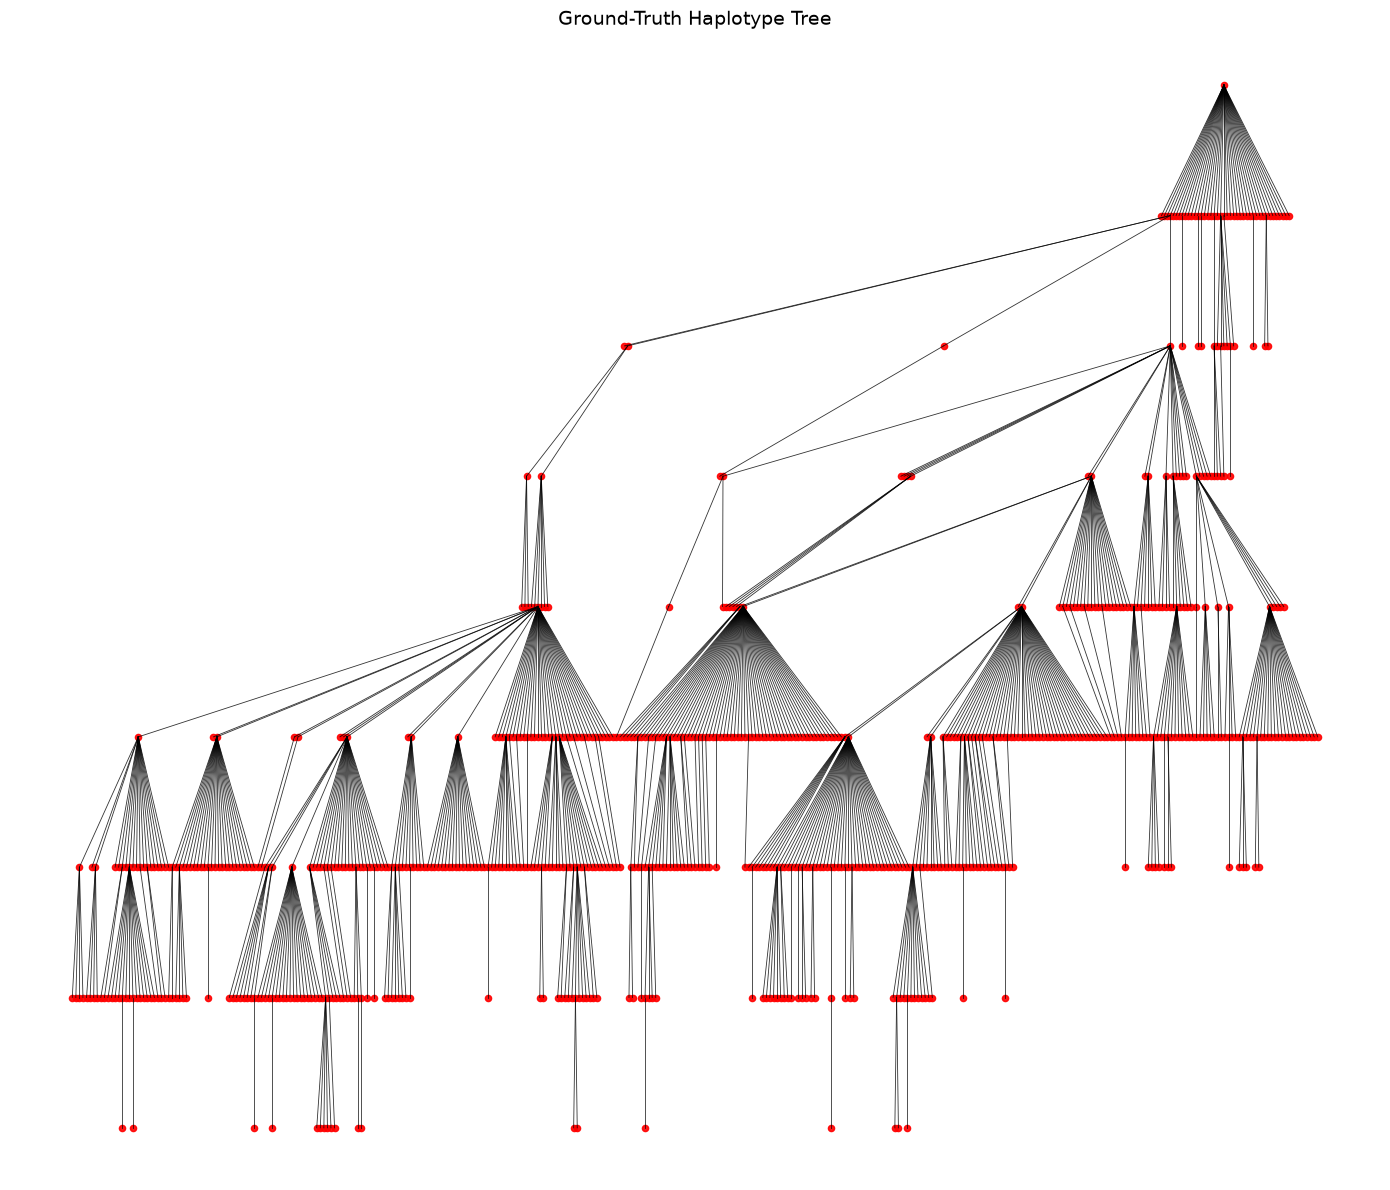

In [5]:
G = build_mutation_tree(sim) # event-base tt
print(f"Policy B mutation tree: nodes={len(G.nodes)}, edges={len(G.edges)}")

H, mutation_nodes, node_events = build_infection_seq_tree(sim) # halpotype-based
plot_mutation_tree(H, title="Ground-Truth Haplotype Tree")

In [51]:
def agents_on_day(sim, day, pool='infectious'):
    '''Agents carrying virus on a given day, rebuilt from the date arrays.'''
    people = sim.people
    start  = people.date_infectious if pool == 'infectious' else people.date_exposed
    start  = np.asarray(start, dtype=float)
    gone   = ((np.asarray(people.date_recovered, dtype=float) <= day) |
              (np.asarray(people.date_dead,      dtype=float) <= day))
    return np.flatnonzero((start <= day) & ~gone)


def sequences_on_day(sim, day, n=None, pool='infectious', seed=42, filepath=None):
    '''Extract the genomes carried on one day, optionally sampling n of them.'''
    eligible = agents_on_day(sim, day, pool=pool)

    if len(eligible) == 0:
        raise ValueError(f"no agents in pool='{pool}' on day {day}")

    chosen = eligible
    if n is not None and n < len(eligible):
        chosen = np.random.default_rng(seed).choice(eligible, size=n, replace=False)
    elif n is not None:
        print(f"  requested {n} but pool holds {len(eligible)}; returning all of them")
    chosen = np.sort(chosen)

    tracker = sim.sequence_tracker
    records = {f"agent_{a}": tracker.reconstruct_haplotype(int(a)) for a in chosen}

    if filepath:
        with open(filepath, 'w') as fh:
            for name, seq in records.items():
                fh.write(f">{name}\n{seq}\n")

    info = dict(day=day, pool=pool, pool_size=len(eligible), agents=chosen,
                records=records, n_records=len(records),
                distinct_haplotypes=len(set(records.values())),
                p_sample=len(records) / len(eligible), path=filepath)
    return info


FOCUS_DAY = 60 # there will be people in pool after last day because of covasim built in recovery
N_SAMPLE  = 10

day_fasta = f"../results/day{FOCUS_DAY}_n{N_SAMPLE}.fasta"
day_info  = sequences_on_day(sim, FOCUS_DAY, n=N_SAMPLE, filepath=day_fasta)


In [52]:
# add Hu-1 to the sampled seqs
hu1 = str(next(SeqIO.parse(REF_FASTA, "fasta")).seq)
with open(day_fasta, "a") as fh:
    fh.write(f">Hu-1\n{hu1}\n")

In [53]:
iqtree_inference = Inference(
    fasta_path=f"/home/eleanor124/projects/covasim4wastewater/docs/tutorials/results/day{FOCUS_DAY}_n{N_SAMPLE}.fasta",
    prefix="inferred_tree", 
    model="JC",
    iqtree_bin="/home/eleanor124/miniforge3/envs/covasim4ww/bin/iqtree",
)
iqtree_inference.run_iqtree_asr()

Running: /home/eleanor124/miniforge3/envs/covasim4ww/bin/iqtree -s /home/eleanor124/projects/covasim4wastewater/docs/tutorials/results/day60_n10.fasta -m JC -asr -redo -pre inferred_tree
IQ-TREE version 3.1.4 for Linux x86 64-bit built Sep 29 2026
Developed by Bui Quang Minh, Thomas Wong, Nhan Ly-Trong, Huaiyan Ren
Contributed by Lam-Tung Nguyen, Dominik Schrempf, Chris Bielow,
Olga Chernomor, Michael Woodhams, Diep Thi Hoang, Heiko Schmidt

Host:    Eleanor (AVX2, FMA3, 15 GB RAM)
Command: /home/eleanor124/miniforge3/envs/covasim4ww/bin/iqtree -s /home/eleanor124/projects/covasim4wastewater/docs/tutorials/results/day60_n10.fasta -m JC -asr -redo -pre inferred_tree
Seed:    160498 (Using SPRNG - Scalable Parallel Random Number Generator)
Time:    Tue Nov 10 16:08:25 2026
Kernel:  AVX+FMA - 1 threads (22 CPU cores detected)

HINT: Use -nt option to specify number of threads because your CPU has 22 cores!
HINT: -nt AUTO will automatically determine the best number of threads to use.

Rea

In [54]:
def sanity_check(tree, node_seqs):
    tree_names = {n.name for n in tree.traverse() if n.name}
    state_names = set(node_seqs.keys())
    only_in_tree = tree_names - state_names
    only_in_state = state_names - tree_names
    print(f"Nodes in tree:  {len(tree_names)}")
    print(f"Nodes in state: {len(state_names)}")
    if only_in_tree:
        print(f"  In tree but not .state ({len(only_in_tree)}): {sorted(only_in_tree)[:10]}")
    if only_in_state:
        print(f"  In .state but not tree ({len(only_in_state)}): {sorted(only_in_state)[:10]}")
    if not only_in_tree and not only_in_state:
        print("  All node names match. \u2713")

In [55]:
def load_state_file(state_path):
    node_seqs = defaultdict(dict)
    with open(state_path) as f:
        header = None
        for line in f:
            line = line.rstrip("\n")
            if not line or line.startswith("#"):
                continue
            fields = line.split("\t")
            if header is None:
                header = fields
                continue
            row = dict(zip(header, fields))
            node_seqs[row["Node"]][int(row["Site"])] = row["State"]
    return node_seqs

def load_tip_sequences(fasta_path):
    tip_seqs = {}
    for record in SeqIO.parse(fasta_path, "fasta"):
        tip_seqs[record.id] = {i + 1: base for i, base in enumerate(str(record.seq))}
    return tip_seqs

iqtree = Tree("inferred_tree.treefile", format=1)
nodes = load_state_file("inferred_tree.state") # every site for every node
tips = load_tip_sequences(f"../results/day{FOCUS_DAY}_n{N_SAMPLE}.fasta")
nodes.update(tips)
sanity_check(iqtree, nodes)

Nodes in tree:  20
Nodes in state: 20
  All node names match. ✓


In [56]:
def get_mutations(parent_seq, child_seq):
    muts = []
    for site, ref_state in parent_seq.items():
        alt_state = child_seq.get(site)
        if alt_state is not None and alt_state != ref_state:
            muts.append((site, ref_state, alt_state))
    return sorted(muts)

def compute_edge_mutations(tree, node_seqs):
    edge_mutations = {}
    for node in tree.traverse("preorder"): # root to tips
        if node.is_root() or not node.name:
            continue
        parent = node.up
        if parent.name in node_seqs and node.name in node_seqs:
            edge_mutations[node.name] = get_mutations(
                node_seqs[parent.name], node_seqs[node.name] # get the variants
            )
        else:
            edge_mutations[node.name] = []
    return edge_mutations

def compute_cumulative_mutations(tree, edge_mutations, root_mutations=None):
    '''Mutations each node carries relative to the reference.

    Args:
        tree (Tree):           the inferred tree
        edge_mutations (dict): node name -> mutations on the edge above it
        root_mutations (list): mutations the root carries relative to the reference
                               (e.g. Hu-1); None treats the root as the reference
    '''
    root_mutations = frozenset(root_mutations or [])
    cumulative = {}
 
    def recurse(node, parent_cumulative):
        current = root_mutations if node.is_root() else parent_cumulative | set(
            edge_mutations.get(node.name, [])
        )
        if node.name:
            cumulative[node.name] = frozenset(current)
        for child in node.children:
            recurse(child, current)
 
    recurse(tree, frozenset())
    return cumulative

In [57]:
def get_mutation_in_long_df_full_tree(mutation_nodes):
    rows = []
    for mutation_state, node in mutation_nodes.items():
        if not mutation_state:
            rows.append({"node": node, "mutation": None})
        for site, ref, alt in mutation_state:
            rows.append({"node": node, "mutation": cv.decode_sequence([ref])+str(int(site)+1)+cv.decode_sequence([alt])})
    df = pd.DataFrame(rows)
    df = df.dropna()
    return df

def get_mutation_in_long_df_inferred_tree(nodes_mutation):
    rows = []
    for node, mutation_state in nodes_mutation.items():
        if not mutation_state:
            rows.append({"node": node, "mutation": None})
        for site, ref, alt in mutation_state:
            rows.append({"node": node, "mutation": ref+str(site)+alt}) # this is already 1-based idx
    df = pd.DataFrame(rows)
    df = df.dropna()
    return df

In [58]:
# Mutations on the root relative to Hu-1, so cumulative mutations are counted from the reference rather than from the inferred root
hu1_seq   = str(next(SeqIO.parse(REF_FASTA, "fasta")).seq)
hu1_sites = {i + 1: base for i, base in enumerate(hu1_seq)} # 1-based, like the .state file
root_mut  = get_mutations(hu1_sites, nodes[iqtree.name])

edge_mut = compute_edge_mutations(iqtree, nodes)
cumultative_mut = compute_cumulative_mutations(iqtree, edge_mut, root_mutations=root_mut)

df_mut_sampled_tree = get_mutation_in_long_df_inferred_tree(cumultative_mut)
df_mut_sampled_tree = df_mut_sampled_tree.dropna() # drop root node
df_mut_sampled_tree

,node,mutation
0,Node1,T3793G
1,Node1,C478A
2,Node1,G21777T
3,Node1,T26573C
4,Node1,T11463C
...,...,...
300,agent_703,T3766A
301,agent_703,T22307C
302,agent_703,C25275A
303,agent_703,T10810G


In [59]:
df_mut_full_tree = get_mutation_in_long_df_full_tree(mutation_nodes) 
df_mut_full_tree

,node,mutation
1,Node_1,G28368T
2,Node_1,C24609G
3,Node_2,T19253A
4,Node_2,G16435T
5,Node_3,A13537C
...,...,...
7921,Node_778,A3193C
7922,Node_778,C10507T
7923,Node_778,A10652C
7924,Node_778,A13949G


In [60]:
full_unique_mut = df_mut_full_tree.drop_duplicates(subset="mutation", keep="first")
inferred_unique_mut = df_mut_sampled_tree.drop_duplicates(subset="mutation", keep="first")
m = pd.merge(full_unique_mut, inferred_unique_mut, how="outer", on="mutation", suffixes=("_full", "_inferred"), indicator=True)
captured = m[m["_merge"] == "both"]
len(captured)/len(full_unique_mut)

0.02614015572858732

Sample infectious people at some rate → You already have this at 1%, 5%, 10%

Reconstruct phylogeny using the genomes associated with the sampled individuals.

Boxplot: x-axis: “Detected” or “Not detected” and y-axis: Number of infected individuals that had that mutation

Of the detected mutations, when was it detected in the inferred tree vs when it actually occurred in the simulation. So starting with a histogram of “lag times” for each sampling rate → For this you will need to infer a time tree using treetime as well

  mutations on the full tree H:      1798
  mutations on the inferred tree:    155
  recovered (on both):               148  (8.2% of H)
  not recovered:                     1650  e.g. T16425A, A13198G, C22227T, A27547T, T3493C, A24302T
  inferred but not on H:             7

  H's mutations ranked by clade size (cumulative)
   top N   clade size    recovered   rate
      10      294-720     10 / 10      100%
      25       26-720     25 / 25      100%
      50        9-720     47 / 50       94%
     100        3-720     64 / 100      64%
     200        2-720     76 / 200      38%
    1798        1-720    148 / 1798      8%


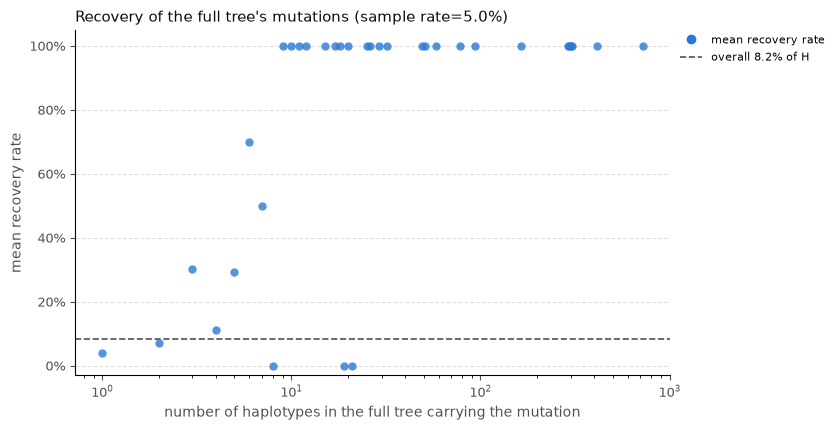

In [46]:
from matplotlib.ticker import PercentFormatter

full     = set(df_mut_full_tree["mutation"])
inferred = set(df_mut_sampled_tree["mutation"])

# Rank H's mutations by clade size (haplotypes in H carrying them)
mutation_counts = df_mut_full_tree["mutation"].value_counts()
full_ranked = pd.DataFrame({"mutation": mutation_counts.index,
                            "counts":   mutation_counts.values})
full_ranked = full_ranked.sort_values("counts", ascending=False, ignore_index=True)
full_ranked["recovered"] = full_ranked["mutation"].isin(inferred)

recovery = full_ranked["recovered"].mean()
lost     = full_ranked[~full_ranked["recovered"]]

print(f"  mutations on the full tree H:      {len(full)}")
print(f"  mutations on the inferred tree:    {len(inferred)}")
print(f"  recovered (on both):               {full_ranked['recovered'].sum()}  ({recovery:.1%} of H)")
print(f"  not recovered:                     {len(lost)}"
      + (f"  e.g. {', '.join(lost['mutation'].head(6))}" if len(lost) else ""))
print(f"  inferred but not on H:             {len(inferred - full)}")

# Cumulative: the N mutations with the largest clades, and the clade sizes they span
print(f"\n  H's mutations ranked by clade size (cumulative)")
print(f"  {'top N':>6}  {'clade size':>11}  {'recovered':>11}  {'rate':>5}")
for n in [10, 25, 50, 100, 200, len(full_ranked)]:
    if n > len(full_ranked):
        continue
    top = full_ranked.head(n)
    clade_range = f"{top['counts'].min()}-{top['counts'].max()}"
    print(f"  {n:>6}  {clade_range:>11}  {top['recovered'].sum():>5} / {n:<5}  {top['recovered'].mean():>5.0%}")

# The data behind the plot: one row per dot.
#   index (counts) = clade size, the x-axis (haplotypes in H carrying the mutation)
#   mean           = share of those mutations recovered, the y-axis
#   size           = how many of H's mutations have exactly this clade size
by = full_ranked.groupby("counts")["recovered"].agg(["mean", "size"])

fig, ax = plt.subplots(figsize=(8.5, 4.4))
ax.scatter(by.index, by["mean"], s=36,
           color="#2a78d6", alpha=0.8, zorder=3, linewidths=0)
ax.axhline(recovery, color="#52514e", lw=1.2, ls="--", zorder=2)

# Legend outside the axes, with fixed-size markers so it does not inherit the bubble sizes
handles = [plt.Line2D([], [], marker="o", ls="", color="#2a78d6", markersize=6,
                      label="mean recovery rate"),
           plt.Line2D([], [], color="#52514e", lw=1.2, ls="--",
                      label=f"overall {recovery:.1%} of H")]
ax.legend(handles=handles, frameon=False, fontsize=8, loc="upper left",
          bbox_to_anchor=(1.01, 1.0), borderaxespad=0)

ax.set_xscale("log")
ax.set_ylim(-0.03, 1.05)
ax.yaxis.set_major_formatter(PercentFormatter(xmax=1))
ax.set_xlabel("number of haplotypes in the full tree carrying the mutation", fontsize=10, color="#52514e")
ax.set_ylabel("mean recovery rate", fontsize=10, color="#52514e")
ax.set_title(f"Recovery of the full tree's mutations (sample rate={N_SAMPLE/1000*100}%)", fontsize=11, color="#0b0b0b", loc="left")
ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.tick_params(labelsize=9, colors="#52514e")
plt.tight_layout()
plt.show()
fig.savefig(f"../results/recovery_by_clade_size_day{FOCUS_DAY}_n{N_SAMPLE}.png", dpi=300, bbox_inches="tight") 


           count        mean         std  min  25%   50%    75%    max
detected                                                              
False     1751.0    1.548258    3.044965  1.0  1.0   1.0    1.0   59.0
True        47.0  149.361702  219.183606  1.0  6.0  35.0  293.5  924.0


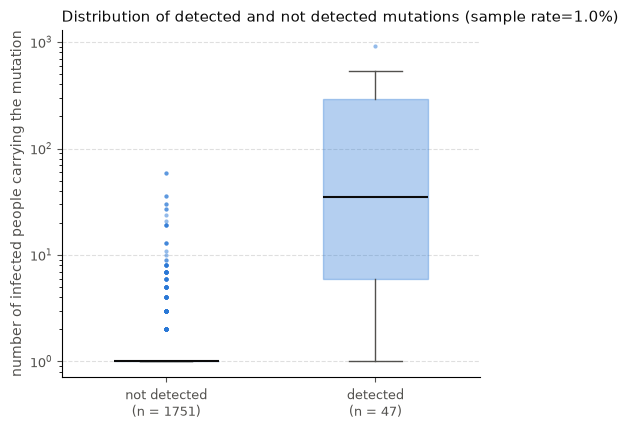

In [61]:
def infected_per_mutation(mutation_nodes, node_events):
    '''Count how many people were infected with a virus carrying each mutation in H.

    A person counts once per mutation, even if they were infected more than once.

    Args:
        mutation_nodes (dict): haplotype (frozenset of (site, ref, alt)) -> node ID, from build_infection_seq_tree()
        node_events (dict):    node ID -> infection event IDs ("<agent>_<date>") with that haplotype

    Returns:
        DataFrame with one row per mutation: 'mutation' (e.g. "T11463C", 1-based site) and 'n_infected'
    '''
    agents_with = defaultdict(set)
    for state, node in mutation_nodes.items():
        agents = {event.rsplit("_", 1)[0] for event in node_events[node]} # drop the date, keep the agent
        for site, ref, alt in state:
            name = cv.decode_sequence([ref]) + str(int(site) + 1) + cv.decode_sequence([alt]) # same format as df_mut_full_tree
            agents_with[name] |= agents
    df = pd.DataFrame({"mutation":   list(agents_with.keys()),
                       "n_infected": [len(a) for a in agents_with.values()]})
    return df


def plot_detection_boxplot(mutation_nodes, node_events, inferred_mutations, log_y=True, ax=None):
    '''Boxplot of how many people carried each mutation, split by whether the inferred tree detected it.

    Args:
        mutation_nodes (dict):     from build_infection_seq_tree()
        node_events (dict):        from build_infection_seq_tree()
        inferred_mutations (set):  mutation names found in the inferred tree, e.g. set(df_mut_sampled_tree["mutation"])
        log_y (bool):              use a log y-axis; counts are heavily skewed, with most mutations in 1-2 people
        ax (Axes):                 axes to draw on; None makes a new figure

    Returns:
        (fig, ax, df) where df has one row per mutation: 'mutation', 'n_infected', 'detected'
    '''
    df = infected_per_mutation(mutation_nodes, node_events)
    df["detected"] = df["mutation"].isin(set(inferred_mutations))

    groups = [df.loc[~df["detected"], "n_infected"], df.loc[df["detected"], "n_infected"]]
    labels = [f"not detected\n(n = {len(groups[0])})", f"detected\n(n = {len(groups[1])})"]

    if ax is None:
        fig, ax = plt.subplots(figsize=(5, 4.4))
    else:
        fig = ax.figure

    ax.boxplot(groups, widths=0.5, patch_artist=True,
               boxprops=dict(facecolor="#2a78d6", alpha=0.35, edgecolor="#2a78d6"),
               medianprops=dict(color="#0b0b0b", lw=1.5),
               whiskerprops=dict(color="#52514e"), capprops=dict(color="#52514e"),
               flierprops=dict(marker="o", markersize=3, markerfacecolor="#2a78d6",
                               markeredgecolor="none", alpha=0.5))
    ax.set_xticks([1, 2])
    ax.set_xticklabels(labels)

    if log_y:
        ax.set_yscale("log")
    ax.set_ylabel("number of infected people carrying the mutation", fontsize=10, color="#52514e")
    ax.set_title(f"Distribution of detected and not detected mutations (sample rate={N_SAMPLE/1000*100}%)",
                 fontsize=11, color="#0b0b0b", loc="left")
    ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
    ax.grid(axis="y", linestyle="--", alpha=0.4)
    ax.tick_params(labelsize=9, colors="#52514e")
    fig.tight_layout()
    return fig, ax, df


fig_box, ax_box, df_infected = plot_detection_boxplot(mutation_nodes, node_events, set(df_mut_sampled_tree["mutation"]))
print(df_infected.groupby("detected")["n_infected"].describe())
plt.show()


In [62]:
import datetime as dt
start      = dt.date.fromisoformat(sim_pars["start_day"])  
tip_date   = start + dt.timedelta(days=FOCUS_DAY)
clock_rate = evo_pars["mol_clock_rate"] * 365 

dates = pd.DataFrame({"name": list(day_info["records"].keys()),
                      "date": tip_date.isoformat()})
dates.loc[len(dates)] = ["Hu-1", start.isoformat()] 
dates.to_csv("treetime_dates.csv", index=False)
dates

,name,date
0,agent_86,2021-03-02
1,agent_88,2021-03-02
2,agent_96,2021-03-02
3,agent_203,2021-03-02
4,agent_442,2021-03-02
5,agent_448,2021-03-02
6,agent_663,2021-03-02
7,agent_703,2021-03-02
8,agent_763,2021-03-02
9,agent_856,2021-03-02


In [63]:
import subprocess

subprocess.run([
    "treetime",
    "--aln",        day_fasta,
    "--tree",       "inferred_tree.treefile",
    "--dates",      "treetime_dates.csv",
    "--clock-rate", str(clock_rate),   # fixed: same-day tips can't estimate it
    "--reroot",     "Hu-1",            # or "--keep-root" if Hu-1 isn't in the tree
    "--clock-filter", "0",             # don't drop tips as clock outliers
    "--gtr",        "JC69",            # match the sim's substitution model
    "--outdir",     "treetime_out",
], check=True)



Attempting to parse dates...
	Using column 'name' as name. This needs match the taxon names in the tree!!
	Using column 'date' as date.

0.00	-TreeAnc: set-up
GTR params are not specified. Creating GTR model with default parameters

0.20	TreeTime.reroot: with method or node: Hu-1

0.22	###TreeTime.run: INITIAL ROUND

0.42	TreeTime.reroot: with method or node: Hu-1

0.42	###TreeTime.run: rerunning timetree after rerooting

0.65	###TreeTime.run: ITERATION 1 out of 2 iterations

0.65	DEPRECATION WARNING. TreeTime.resolve_polytomies: You are resolving
    	polytomies using the old 'greedy' mode. This is not well suited for large
    	polytomies. Stochastic resolution will become the default in future
    	versions. To switch now, rerun with the flag `--stochastic-resolve`. To
    	keep using the greedy method in the future, run with `--greedy-resolve`

0.92	###TreeTime.run: ITERATION 2 out of 2 iterations

1.18	###TreeTime.run: CONVERGED

--- molecular clock model (saved as treetime_out/m

CompletedProcess(args=['treetime', '--aln', '../results/day60_n10.fasta', '--tree', 'inferred_tree.treefile', '--dates', 'treetime_dates.csv', '--clock-rate', '0.0036500000000000005', '--reroot', 'Hu-1', '--clock-filter', '0', '--gtr', 'JC69', '--outdir', 'treetime_out'], returncode=0)

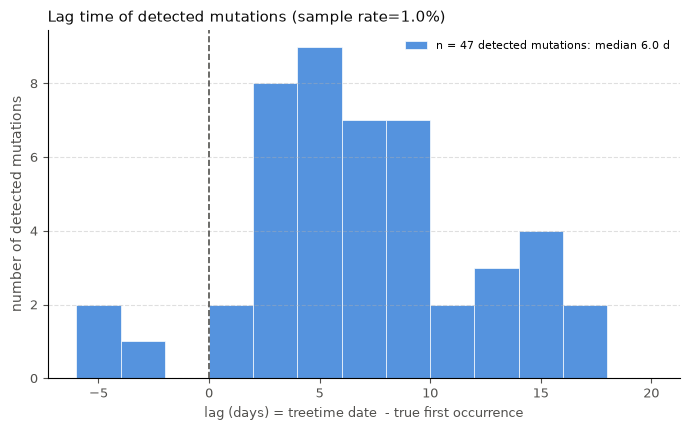

In [64]:
import json
import datetime as dt
from treetime.utils import datetime_from_numeric

def first_occurrence(sim):
    '''Sim day each mutation first appeared: the earliest infection whose transmission produced it.

    Args:
        sim (Sim): the finished sim, run with store_infection_log=True

    Returns:
        dict of mutation name (e.g. "T11463C", 1-based site) -> sim day
    '''
    infection_log = getattr(sim, "infection_log", None) or sim.people.infection_log
    first = {}
    for entry in infection_log:
        for site, ref, alt in entry.get("branch_mutations", []):
            name = cv.decode_sequence([ref]) + str(int(site) + 1) + cv.decode_sequence([alt]) # same format as df_mut_full_tree
            first[name] = min(first.get(name, np.inf), float(entry["date"]))
    return first


def lag_times(sim, treetime_dir="treetime_out", when="mid"):
    '''Lag between when each detected mutation is dated on the TreeTime tree and when it truly arose in the simulation.'''
    start = pd.Timestamp(sim["start_day"]).to_pydatetime() # accepts a string or a date

    # Node dates (as fractional sim days) and parents, from TreeTime's JSON tree. The JSON is used
    # rather than timetree.nexus because Biopython drops internal node names (Node1, ...) from the nexus
    with open(os.path.join(treetime_dir, "auspice_tree.json")) as fh:
        tree_json = json.load(fh)["tree"]
    node_day, parent_of = {}, {}
    def walk(node, parent=None):
        decimal_year = node["node_attrs"]["num_date"]["value"]
        node_day[node["name"]]  = (datetime_from_numeric(decimal_year) - start).total_seconds() / 86400
        parent_of[node["name"]] = parent
        for child in node.get("children", []):
            walk(child, node["name"])
    walk(tree_json)

    # Mutations on each branch, named like the full tree's (ref + 1-based site + alt)
    branch_mut = pd.read_csv(os.path.join(treetime_dir, "branch_mutations.txt"), sep="\t")
    branch_mut["mutation"] = branch_mut["state1"] + branch_mut["pos"].astype(str) + branch_mut["state2"]

    child_day  = branch_mut["node"].map(node_day)
    parent_day = branch_mut["node"].map(parent_of).map(node_day)
    branch_mut["inferred_day"] = {"mid": (parent_day + child_day) / 2, "parent": parent_day, "child": child_day}[when]

    # A mutation can sit on more than one branch (homoplasy or reconstruction noise): keep its earliest date
    df = (branch_mut.sort_values("inferred_day")
                    .drop_duplicates(subset="mutation", keep="first")[["mutation", "node", "inferred_day"]])

    true_day = first_occurrence(sim)
    df["true_day"] = df["mutation"].map(true_day)
    n_not_in_sim = df["true_day"].isna().sum()
    if n_not_in_sim:
        print(f"  {n_not_in_sim} mutation(s) on the TreeTime tree never occurred in the sim; left out")
    df = df.dropna(subset=["true_day"])
    df["lag"] = df["inferred_day"] - df["true_day"]
    return df.reset_index(drop=True)


def plot_lag_histogram(lags, when="mid", bin_width=2, ax=None):
    '''Histogram of lag times for detected mutations.

    Args:
        lags (DataFrame or dict): output of lag_times(), or {label: DataFrame} to overlay several sampling rates
        when (str):               which branch point was used, for the axis label
        bin_width (float):        histogram bin width in days
        ax (Axes):                axes to draw on; None makes a new figure

    Returns:
        (fig, ax)
    '''
    if isinstance(lags, pd.DataFrame):
        lags = {f"n = {len(lags)} detected mutations": lags}

    if ax is None:
        fig, ax = plt.subplots(figsize=(7, 4.4))
    else:
        fig = ax.figure

    all_lags = np.concatenate([df["lag"].to_numpy() for df in lags.values()])
    lo = np.floor(all_lags.min() / bin_width) * bin_width
    hi = np.ceil(all_lags.max() / bin_width) * bin_width + bin_width
    bins = np.arange(lo, hi + bin_width, bin_width)

    colors = ["#2a78d6", "#d6762a", "#3a9a5b", "#8a4fbf"]
    for (label, df), color in zip(lags.items(), colors):
        ax.hist(df["lag"], bins=bins, color=color, alpha=0.6 if len(lags) > 1 else 0.8,
                edgecolor="white", linewidth=0.6,
                label=f"{label}: median {df['lag'].median():.1f} d")
    ax.axvline(0, color="#52514e", lw=1.2, ls="--", zorder=3)

    branch_point = {"mid": "branch midpoint", "parent": "start of branch", "child": "end of branch"}[when]
    ax.set_xlabel(f"lag (days) = treetime date  - true first occurrence", fontsize=9, color="#52514e")
    ax.set_ylabel("number of detected mutations", fontsize=10, color="#52514e")
    ax.set_title(f"Lag time of detected mutations (sample rate={N_SAMPLE/1000*100}%)",
                 fontsize=11, color="#0b0b0b", loc="left")
    ax.legend(frameon=False, fontsize=8, loc="upper right")
    ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
    ax.grid(axis="y", linestyle="--", alpha=0.4)
    ax.tick_params(labelsize=9, colors="#52514e")
    fig.tight_layout()
    return fig, ax


df_lag = lag_times(sim, treetime_dir="treetime_out", when="mid")
fig_lag, ax_lag = plot_lag_histogram(df_lag, when="mid")
plt.show()
fig_lag.savefig(f"../results/lag_time_day{FOCUS_DAY}_n{N_SAMPLE}.png", dpi=300, bbox_inches="tight")
